**Laboratorium nr 4**


Zadanie 1

Wczytaj dane z pliku ds_salaries.csv, a następnie oblicz średnią arytmetyczną i medianę dla kolumny salary_in_usd. Zidentyfikuj wartości odstające na podstawie odchylenia standardowego i odfiltruj rekordy, których wartość przekracza 3-krotność odchylenia standardowego od średniej. Na wykresie pudełkowym narysuj rozkład dla kolumny salary_in_usd przed i po filtracji.




Wczytanie Danych

In [28]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "ds_salaries.csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "ruchi798/data-science-job-salaries",
  file_path,
)

/tmp/ipykernel_6745/2559027026.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'data-science-job-salaries' dataset.


Średnia: 112297.87 USD
Mediana: 101570.00 USD
Usunięto rekordów odstających: 8


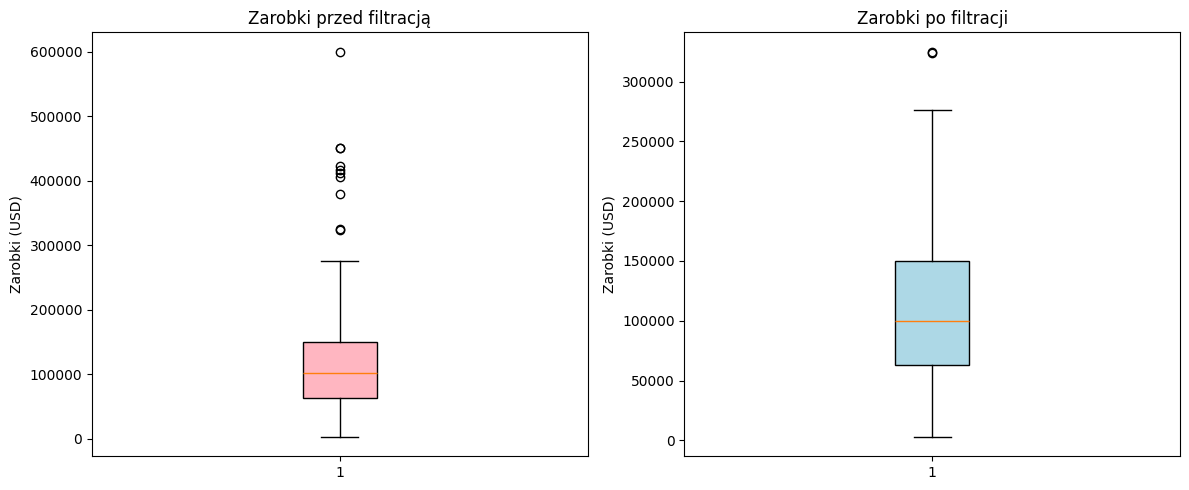

In [32]:
import matplotlib.pyplot as plt

zarobki_przed = df["salary_in_usd"]

srednia = zarobki_przed.mean()
mediana = zarobki_przed.median()
odchylenie = zarobki_przed.std()

print(f"Średnia: {srednia:.2f} USD")
print(f"Mediana: {mediana:.2f} USD")

# Filtracja wartości przekraczających 3 odchylenia standardowe od średniej
dolna_granica = srednia - 3 * odchylenie
gorna_granica = srednia + 3 * odchylenie

dane_bez_odstajacych = df[
    (zarobki_przed >= dolna_granica) & (zarobki_przed <= gorna_granica)
]
zarobki_po = dane_bez_odstajacych["salary_in_usd"]

print(f"Usunięto rekordów odstających: {len(zarobki_przed) - len(zarobki_po)}")

fig, osie = plt.subplots(1, 2, figsize=(12, 5))

osie[0].boxplot(
    zarobki_przed,
    patch_artist=True,
    boxprops=dict(facecolor="lightpink")
)
osie[0].set_title("Zarobki przed filtracją")
osie[0].set_ylabel("Zarobki (USD)")

osie[1].boxplot(
    zarobki_po,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue")
)
osie[1].set_title("Zarobki po filtracji")
osie[1].set_ylabel("Zarobki (USD)")

plt.tight_layout()
plt.show()

Zadanie 2

Wczytaj dane z pliku googleplaystore.csv, który zawiera informacje o aplikacjach w sklepie Google Play. Na początku sprawdź, czy w kolumnie Rating występują puste rekordy (braki danych) – jeżeli tak, to je usuń. Następnie na podstawie kolumny Rating oblicz dominantę i narysuj histogram ocen.

Wczytanie danych

In [43]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "googleplaystore.csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "lava18/google-play-store-apps",
  file_path,
)

/tmp/ipykernel_6745/351309471.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'google-play-store-apps' dataset.


Braki przed czyszczeniem: 1474
Dominanta ocen: 4.4


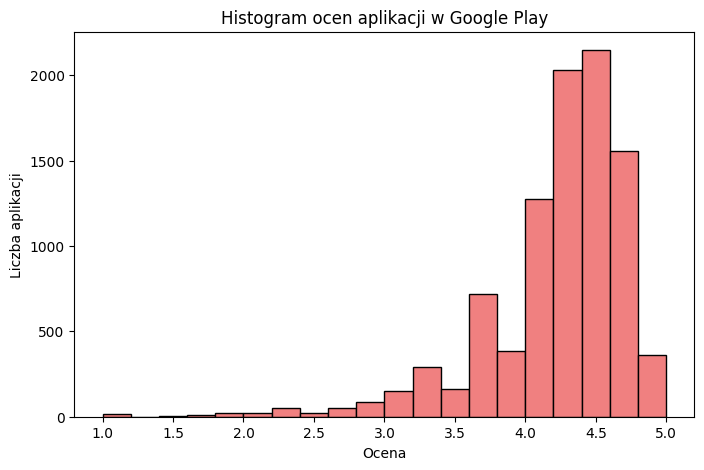

In [44]:
import matplotlib.pyplot as plt

print("Braki przed czyszczeniem:", df["Rating"].isna().sum())

dane_czyste = df.dropna(subset=["Rating"])
dane_czyste = dane_czyste[dane_czyste["Rating"] <= 5]

dominanta = dane_czyste["Rating"].mode()[0]
print(f"Dominanta ocen: {dominanta}")

plt.figure(figsize=(8, 5))
plt.hist(dane_czyste["Rating"], bins=20, color="lightcoral", edgecolor="black")
plt.title("Histogram ocen aplikacji w Google Play")
plt.xlabel("Ocena")
plt.ylabel("Liczba aplikacji")
plt.show()

Zadanie 3

Wczytaj dane z pliku KAG_energydata_complete.csv. Sprawdź, czy nie występują braki danych w kolumnach od T1 do T9 – jeżeli wystąpią, usuń wybrakowane rekordy. Następnie przeanalizuj temperatury i oblicz wariancję oraz odchylenie standardowe dla każdego pomieszczenia, wskazując, które z nich charakteryzuje się najbardziej stabilną temperaturą. Korzystając z histogramów, przedstaw rozkład temperatur na wykresie.



Wczytanie danych

In [40]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "KAG_energydata_complete.csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "loveall/appliances-energy-prediction",
  file_path,)

/tmp/ipykernel_6745/4292293560.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'appliances-energy-prediction' dataset.


Braki w kolumnach temperatur: 0
T1 -> Wariancja: 2.58, Odchylenie std: 1.61
T2 -> Wariancja: 4.81, Odchylenie std: 2.19
T3 -> Wariancja: 4.02, Odchylenie std: 2.01
T4 -> Wariancja: 4.17, Odchylenie std: 2.04
T5 -> Wariancja: 3.40, Odchylenie std: 1.84
T6 -> Wariancja: 37.09, Odchylenie std: 6.09
T7 -> Wariancja: 4.45, Odchylenie std: 2.11
T8 -> Wariancja: 3.83, Odchylenie std: 1.96
T9 -> Wariancja: 4.06, Odchylenie std: 2.01

Najbardziej stabilna temperatura: T1 (odchylenie std: 1.61)


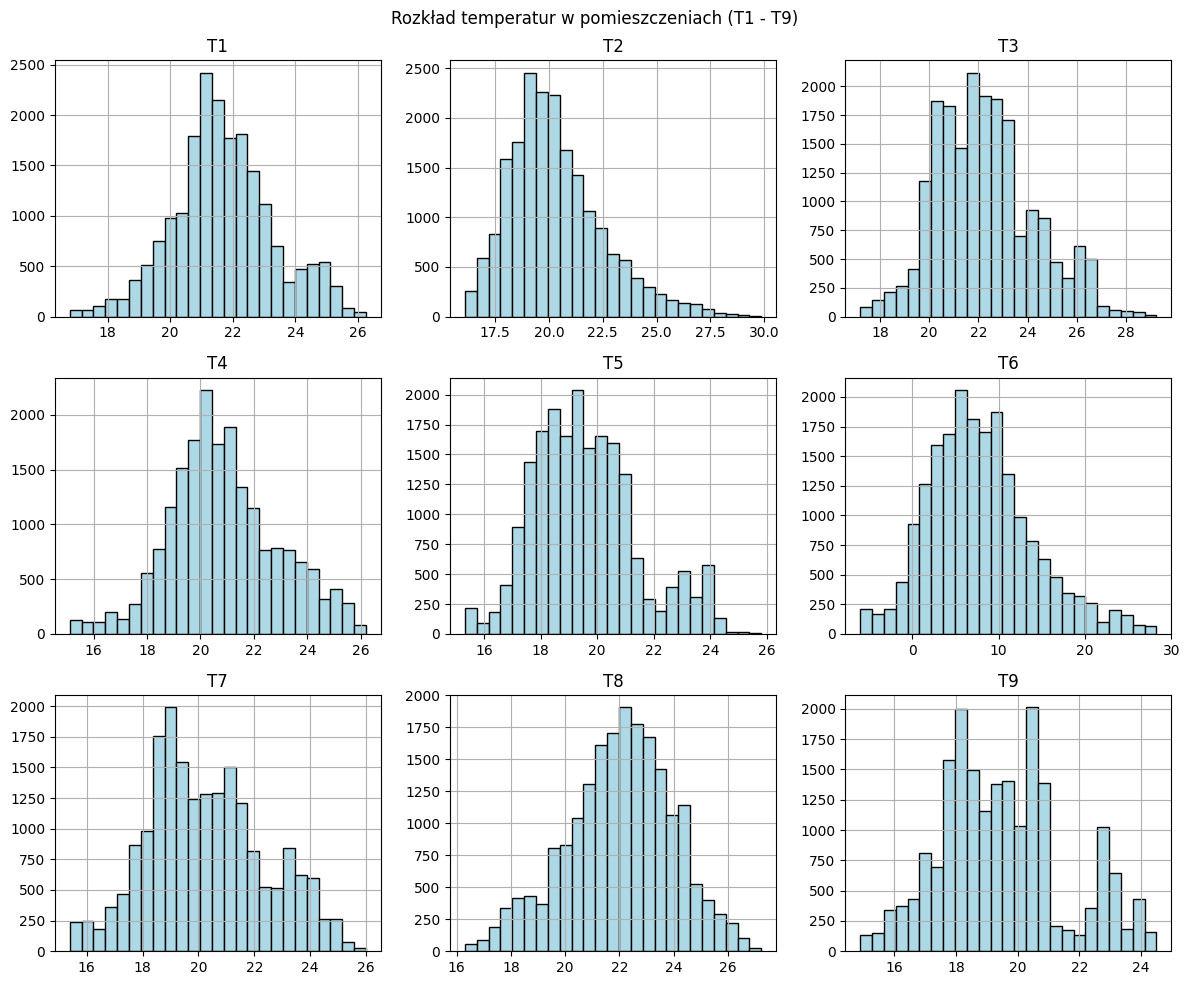

In [41]:
import matplotlib.pyplot as plt

kolumny_temp = ["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "T9"]

print("Braki w kolumnach temperatur:", df[kolumny_temp].isna().sum().sum())
dane_energia = df.dropna(subset=kolumny_temp)

wariancja = dane_energia[kolumny_temp].var()
odchylenie_std = dane_energia[kolumny_temp].std()

for kolumna in kolumny_temp:
    print(f"{kolumna} -> Wariancja: {wariancja[kolumna]:.2f}, Odchylenie std: {odchylenie_std[kolumna]:.2f}")

najstabilniejsze = odchylenie_std.idxmin()
print(f"\nNajbardziej stabilna temperatura: {najstabilniejsze} (odchylenie std: {odchylenie_std[najstabilniejsze]:.2f})")

dane_energia[kolumny_temp].hist(bins=25, figsize=(12, 10), color="lightblue", edgecolor="black")
plt.suptitle("Rozkład temperatur w pomieszczeniach (T1 - T9)")
plt.tight_layout()
plt.show()

Zadanie 4

Korzystając ze zbioru NYC Taxis (taxis) wbudowanego w bibliotekę seaborn, załaduj dane do ramki danych. Sprawdź, czy w kolumnie distance występują braki danych oraz wartości nietypowe (kursy o ujemnej lub zerowej długości). Jeśli takie występują, usuń te rekordy. Oblicz wartości kurtozy i skośności dla kolumny distance. Następnie dodaj nową kolumnę o nazwie distance_log, którą uzupełnisz zlogarytmowaną wartością dystansu w tym celu zastosuj funkcję np.log1p(df["distance"]). Przygotuj wykresy gęstości dla kolumn distance oraz distance_log. Aby to zrobić, zapoznaj się z wykresem KDE (Kernel Density Estimation) dostępnym w bibliotece seaborn.

Braki w distance: 0
Kursy <= 0: 51
Skośność: 3.00
Kurtoza: 11.09


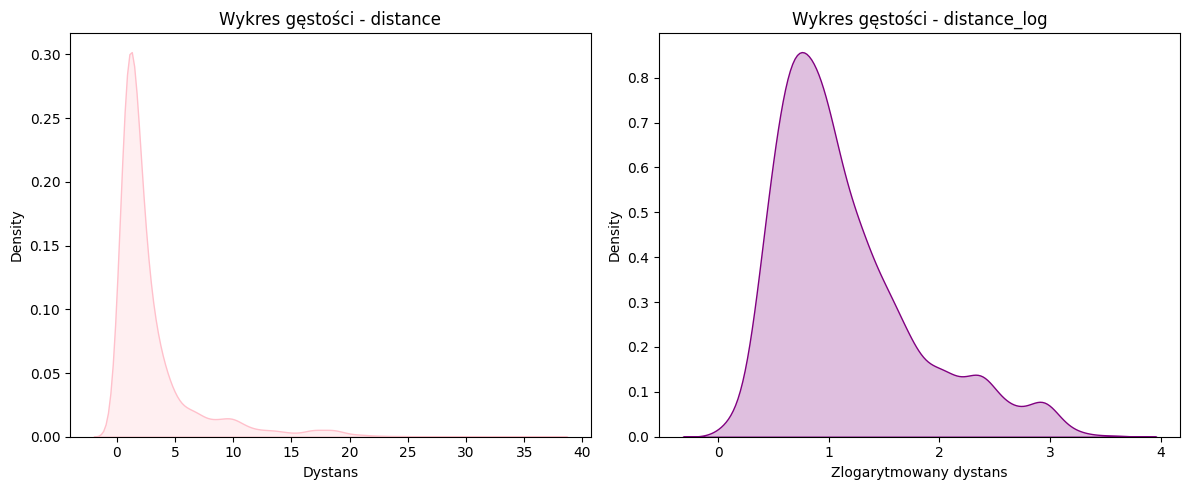

In [14]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

dane_taxi = sns.load_dataset("taxis")

print("Braki w distance:", dane_taxi["distance"].isna().sum())
print("Kursy <= 0:", (dane_taxi["distance"] <= 0).sum())

dane_taxi = dane_taxi.dropna(subset=["distance"])
dane_taxi = dane_taxi[dane_taxi["distance"] > 0].copy()

skosnosc = dane_taxi["distance"].skew()
kurtoza = dane_taxi["distance"].kurt()

print(f"Skośność: {skosnosc:.2f}")
print(f"Kurtoza: {kurtoza:.2f}")

dane_taxi["distance_log"] = np.log1p(dane_taxi["distance"])

fig, osie = plt.subplots(1, 2, figsize=(12, 5))

sns.kdeplot(data=dane_taxi, x="distance", fill=True, ax=osie[0], color="pink")
osie[0].set_title("Wykres gęstości - distance")
osie[0].set_xlabel("Dystans")

sns.kdeplot(data=dane_taxi, x="distance_log", fill=True, ax=osie[1], color="purple")
osie[1].set_title("Wykres gęstości - distance_log")
osie[1].set_xlabel("Zlogarytmowany dystans")

plt.tight_layout()
plt.show()